In [1]:
config_path = "config/params.yaml"
mode = "default"

In [2]:
# Parameters
config_path = "config/params.yaml"


# 15 — Evaluasi holdout

**Tujuan:** membuka minggu `w3` satu kali dan menguji hipotesis konfirmatori. Tidak ada fitur, parameter, atau ambang yang diubah setelah holdout dibuka.
Semua metrik dihitung terhadap label teramati `s`, yaitu akun hilang, bukan pelanggaran.

In [3]:
import json
from datetime import UTC, datetime

import numpy as np
import pandas as pd

from ghremoval.analysis import FORWARD_ARMS, aurt_delta_bootstrap, block_width, bootstrap_gain, cells_of, checkpoint_scores, coordination_ladder, du_name_baselines, f3_sensitivity, ladder, latency_table, pilot_scores, policy_results, policy_sensitivity, rates_by_week, score_row
from ghremoval.config import load_context
from ghremoval.evaluate import holm, paired_cluster_bootstrap, within_cell_auc
from ghremoval.gates import gate_passed
from ghremoval.models.fit import arm_mask, load_stage
from ghremoval.quality import Checks
from ghremoval.report import save_table, write_numbers
from ghremoval.runlog import RunLog, git_commit
from ghremoval.splits import id_block_groups
from ghremoval.viz import new_figure, save_figure

ctx = load_context(config_path)
run = RunLog("15_holdout_evaluation", ctx.paths.run_log, ctx.paths.root)
checks = Checks()
marker = ctx.paths.results / "holdout_opened.json"

## 0. Penjaga: holdout hanya boleh dibuka satu kali

File penanda ditulis **sebelum** label holdout dibaca.

In [4]:
if not ctx.p.holdout_open:
    raise RuntimeError("holdout_open masih false")
if not gate_passed(ctx, "D"):
    raise RuntimeError("Gerbang D belum lewat")
if marker.exists():
    raise RuntimeError("Holdout sudah pernah dibuka. Run kedua harus dicatat di docs/DEVIATIONS.md dan dijalankan dengan sengaja.")
marker.write_text(json.dumps({"opened_at_utc": datetime.now(UTC).isoformat(timespec="seconds"), "git_commit": git_commit(ctx.paths.root)}, indent=2) + "\n")
best = json.loads((ctx.paths.results / "best_params.json").read_text())
dev_decisions = json.loads((ctx.paths.results / "model_decisions_dev.json").read_text())
split_dev = json.loads((ctx.paths.results / "split_audit_dev.json").read_text())
effective_delta = dev_decisions["effective_delta"]
decision_cfg = ctx.p.locked["decision"]
reps = decision_cfg["bootstrap_reps"]
min_pos = decision_cfg["min_positives_per_stratum"]
print("ambang AP efektif:", round(effective_delta, 4), "lebar blok:", block_width(ctx))

ambang AP efektif: 0.01 lebar blok: 20000


## 1. Data holdout dan tangga model

In [5]:
data = load_stage(ctx, "final", 60)
assert set(data.test["week"].unique()) == {"w3"}
result = ladder(ctx, "final", data, best)
table = pd.concat([pd.DataFrame(result["rows"]), pd.DataFrame(du_name_baselines(ctx, data))], ignore_index=True)
save_table(table, "tab_models_by_stratum_final", "Model ladder on holdout (observed label)")
scores = {name: value[0] for name, value in result["models"].items()}
y = data.test["is_gone"].to_numpy().astype(int)
strata = data.test["stratum"].to_numpy()
f3 = arm_mask(data.train, data.test, "F3_forward_batch_excluded", ctx)
f3_519_pos = int(y[f3 & (strata == "5-19")].sum())
print("positif F3 stratum 5-19:", f3_519_pos)
table[table.arm == "F3_forward_batch_excluded"][["model", "n", "n_pos", "base_5-19", "ap_all", "ap_5-19", "ap_20+", "within_cell_auc", "p_at_100"]]

positif F3 stratum 5-19: 471


,model,n,n_pos,base_5-19,ap_all,ap_5-19,ap_20+,within_cell_auc,p_at_100
2,B0_rank_events,24249,504,0.020201,0.031078,0.025224,0.098207,0.490514,0.09
5,B1_age,24249,504,0.020201,0.074623,0.073360,0.115406,0.500000,0.13
8,B2_xgb,24249,504,0.020201,0.089288,0.084127,0.151569,0.500000,0.18
11,B2_lr,24249,504,0.020201,0.089459,0.084769,0.141281,0.500000,0.18
14,M_behav_xgb,24249,504,0.020201,0.270089,0.257593,0.377616,0.735568,0.72
17,M_behav_lr,24249,504,0.020201,0.251738,0.239237,0.405909,0.697403,0.67
20,M_behav_mlp,24249,504,0.020201,0.289957,0.279434,0.410205,0.697638,0.74
23,M_robust_xgb,24249,504,0.020201,0.207109,0.204985,0.249317,0.705358,0.58
25,B3_du_intervals,24249,504,0.020201,0.150462,0.155033,0.186683,NaN,0.50
27,B3_name_heuristic,24249,504,0.020201,0.036457,0.036592,0.045780,NaN,0.09


## 2. RQ1: H1a dan H1b

In [6]:
h1a = bootstrap_gain(ctx, data, scores["M_behav_xgb"], scores["B2_xgb"], "F3_forward_batch_excluded", "5-19")
cells = cells_of(data.test)
clusters = id_block_groups(data.test["actor_id"].to_numpy(), block_width(ctx))
behav = scores["M_behav_xgb"]


def within_minus_half(idx: np.ndarray) -> float:
    kept = idx[f3[idx]]
    return within_cell_auc(y[kept], behav[kept], cells[kept]) - 0.5


h1b_value = within_cell_auc(y[f3], behav[f3], cells[f3])
h1b = paired_cluster_bootstrap(within_minus_half, clusters, reps, ctx.p.project["seed"])
print("H1a:", h1a)
print("H1b AUC dalam sel:", round(h1b_value, 4), "CI:", round(h1b["low"] + 0.5, 4), round(h1b["high"] + 0.5, 4))

H1a: {'delta': 0.17346627039468782, 'low': 0.09960058871888045, 'high': 0.24854379044470498, 'p_one_sided': 0.0, 'n_reps': 2000, 'n_clusters_with_pos': 329, 'delta_without_largest_cluster': 0.16979962438815882}
H1b AUC dalam sel: 0.7356 CI: 0.7 0.7707


## 3. RQ2: H2a dari nb09 dan H2b

H2b membandingkan estimasi validasi silang dengan AP forward pada `F2`, keduanya pada konfigurasi pilot.
Bootstrap hanya atas klaster holdout; estimasi CV diperlakukan tetap.

In [7]:
pilot_behav = pilot_scores("M_behav", data.train, [data.test], ctx)[0]
f2 = arm_mask(data.train, data.test, "F2_forward_new_accounts", ctx)
primary_arm = f"A3_idblock_{block_width(ctx)}"
cv_a1, cv_a3 = split_dev["cv_ap_5_19"]["A1_random"], split_dev["cv_ap_5_19"][primary_arm]
from sklearn.metrics import average_precision_score  # noqa: E402

f2_519 = f2 & (strata == "5-19")
forward_ap = average_precision_score(y[f2_519], pilot_behav[f2_519])


def error_gap(idx: np.ndarray) -> float:
    kept = idx[f2_519[idx]]
    if y[kept].sum() == 0:
        return float("nan")
    value = average_precision_score(y[kept], pilot_behav[kept])
    return abs(cv_a1 - value) - abs(cv_a3 - value)


h2b_observed = abs(cv_a1 - forward_ap) - abs(cv_a3 - forward_ap)
h2b = paired_cluster_bootstrap(error_gap, clusters, reps, ctx.p.project["seed"])
audit = pd.DataFrame([{"arm": "A1_random_cv", "ap_5_19": cv_a1}, {"arm": f"{primary_arm}_cv", "ap_5_19": cv_a3}, {"arm": "F2_forward_holdout", "ap_5_19": forward_ap}])
save_table(audit, "tab_split_audit_final", "Cross-validation estimates against forward holdout, 5-19 events")
print({"forward_ap": forward_ap, "cv_a1": cv_a1, "cv_a3": cv_a3, "h2b_observed": h2b_observed, **h2b})

{'forward_ap': 0.2600004346920868, 'cv_a1': 0.39656691693022, 'cv_a3': 0.35463421821914987, 'h2b_observed': 0.04193269871107014, 'low': 0.04193269871107014, 'high': 0.04193269871107014, 'p_one_sided': 0.007, 'n_reps': 2000}


## 4. RQ4: latensi dan kebijakan adaptif

In [8]:
latency = pd.DataFrame(latency_table(ctx, "final", best))
save_table(latency, "tab_latency_final", "Average precision by observation window on holdout")
cfg = ctx.p.locked["policy"]
primary = cfg["primary_target_precision"]
policy_rows, comparisons, keep = [], {}, {}
for cohort in ("fixed", "deployable"):
    behav_scores = checkpoint_scores(ctx, "final", cohort, "M_behav", best["xgb"])
    base_scores = checkpoint_scores(ctx, "final", cohort, "B2", None)
    train_arm = load_stage(ctx, "final", 60, cohort=cohort).train
    for arm in ("F2_forward_new_accounts", "F3_forward_batch_excluded"):
        adaptive = policy_results(ctx, behav_scores, arm, train_arm)
        baseline = policy_results(ctx, base_scores, arm, train_arm)
        keep[(cohort, arm)] = (adaptive, behav_scores)
        policy_rows += [{"cohort": cohort, "arm": arm, "model": "M_behav", **r} for r in adaptive["rows"]]
        policy_rows += [{"cohort": cohort, "arm": arm, "model": "B2_first_cross", **r} for r in baseline["rows"] if r["policy"] == "adaptive"]
        if ("adaptive", primary) in adaptive["times"] and ("best_fixed", primary) in adaptive["times"]:
            comparisons[f"{cohort}|{arm}"] = {"best_fixed_window": adaptive["best_fixed"].get(primary), **aurt_delta_bootstrap(ctx, behav_scores, adaptive["times"][("adaptive", primary)], adaptive["times"][("best_fixed", primary)], adaptive["mask"])}
        else:
            comparisons[f"{cohort}|{arm}"] = {"status": "target precision tidak tercapai", "delta": float("nan"), "low": float("nan"), "high": float("nan"), "p_one_sided": float("nan")}
policy_final = pd.DataFrame(policy_rows)
save_table(policy_final, "tab_policy_final", "Early-flagging policy on holdout (observed label)")
h4a = comparisons["fixed|F3_forward_batch_excluded"]
(ctx.paths.results / "policy_final.json").write_text(json.dumps(comparisons, indent=2, default=float) + "\n")
print("H4a:", h4a)
policy_final[(policy_final.target == primary) & (policy_final.cohort == "fixed") & (policy_final.arm == "F3_forward_batch_excluded")].reindex(columns=["model", "policy", "status", "n_flagged", "precision", "recall", "aurt", "median_time_tp"])

H4a: {'best_fixed_window': 30, 'delta': 0.0582010582010582, 'low': 0.013932370928744131, 'high': 0.12040132383067362, 'p_one_sided': 0.0, 'n_reps': 2000}


,model,policy,status,n_flagged,precision,recall,aurt,median_time_tp
27,M_behav,adaptive,ok,78.0,0.769231,0.119048,0.065344,30.0
28,M_behav,fixed_5,ok,15.0,1.000000,0.029762,0.027778,5.0
29,M_behav,fixed_10,ok,13.0,0.923077,0.023810,0.020635,10.0
30,M_behav,fixed_15,ok,35.0,0.857143,0.059524,0.047619,15.0
31,M_behav,fixed_30,ok,9.0,0.666667,0.011905,0.007143,30.0
32,M_behav,fixed_60,ok,63.0,0.873016,0.109127,0.021825,60.0
40,B2_first_cross,adaptive,target tidak tercapai pada kalibrasi,NaN,NaN,NaN,NaN,NaN


## 5. RQ5: fitur koordinasi

In [9]:
coordination = coordination_ladder(ctx, "final", best)
save_table(pd.DataFrame(coordination["rows"]), "tab_coord_ablation_final", "Coordination ablation on holdout (observed label)")
h5 = bootstrap_gain(ctx, coordination["data"], coordination["scores"]["M_coord"], coordination["scores"]["M_behav"], "F3_forward_batch_excluded", "5-19")
print("H5:", h5)

H5: {'delta': 0.10728314756761514, 'low': 0.0784753624981823, 'high': 0.13980207203605013, 'p_one_sided': 0.0, 'n_reps': 2000, 'n_clusters_with_pos': 329, 'delta_without_largest_cluster': 0.10810797438178815}


## 5b. Sensitivitas

Semua bagian ini eksploratif dan tidak mengubah keputusan hipotesis.
Pada perbandingan precision yang disamakan, `q` dipilih memakai label holdout untuk kedua kebijakan, jadi hasilnya bukan kinerja yang bisa dicapai saat dipakai.

In [10]:
policy_sens = pd.DataFrame([{"cohort": cohort, "arm": arm, **row} for (cohort, arm), (out, behav_out) in keep.items() for row in policy_sensitivity(ctx, behav_out, out, primary)])
save_table(policy_sens, "tab_policy_sensitivity_final", "Policy sensitivity on holdout: other horizons and matched observed precision (exploratory, observed label)")
f3_sens = pd.DataFrame(f3_sensitivity(ctx, data, {name: scores[name] for name in ("B2_xgb", "M_behav_xgb")}))
save_table(f3_sens, "tab_f3_sensitivity_final", "Forward arm excluding ID blocks with any training account (exploratory, observed label)")
followup = pd.DataFrame(rates_by_week(data))
save_table(followup, "tab_followup_by_week_final", "Observed disappearance rate by week and stratum (observed label)")
print(policy_sens.to_string())
print(f3_sens.to_string())
print(followup.to_string())

        cohort                        arm           analysis  target status  horizon  aurt_adaptive  aurt_best_fixed     delta  level      policy  window      q  n_flagged  precision    recall      aurt  median_time_tp
0        fixed    F2_forward_new_accounts            horizon     0.7     ok     65.0       0.071772         0.011757  0.060016    NaN         NaN     NaN    NaN        NaN        NaN       NaN       NaN             NaN
1        fixed    F2_forward_new_accounts            horizon     0.7     ok     90.0       0.090652         0.014556  0.076096    NaN         NaN     NaN    NaN        NaN        NaN       NaN       NaN             NaN
2        fixed    F2_forward_new_accounts  matched_precision     0.7     ok      NaN            NaN              NaN       NaN    0.5    adaptive     NaN  0.265      223.0   0.547085  0.177584  0.113052            15.0
3        fixed    F2_forward_new_accounts  matched_precision     0.7     ok      NaN            NaN              NaN       N

## 6. Keputusan dengan koreksi Holm

In [11]:
testable = f3_519_pos >= min_pos
p_values = {"H1a": h1a["p_one_sided"], "H2a": split_dev["ratio_p"], "H4a": h4a.get("p_one_sided", float("nan")), "H5": h5["p_one_sided"]}
adjusted = holm(p_values)


def decide(name: str, estimate: float, low: float, passes: bool) -> str:
    if name != "H2a" and not testable:
        return "tidak dapat diuji"
    if np.isnan(estimate) or np.isnan(low):
        return "tidak dapat diuji"
    return "didukung" if passes and adjusted.get(name, 0.0) < 0.05 else "tidak didukung"


h2a_low = split_dev["ratio_ci"][0]
summary = [
    {"hypothesis": "H1a", "statement": "M_behav > B2, F3, 5-19", "estimate": h1a["delta"], "ci_low": h1a["low"], "ci_high": h1a["high"], "p_holm": adjusted["H1a"], "decision": decide("H1a", h1a["delta"], h1a["low"], h1a["low"] > 0 and h1a["delta"] >= effective_delta)},
    {"hypothesis": "H1b", "statement": "AUC dalam sel > 0.5, F3", "estimate": h1b_value, "ci_low": h1b["low"] + 0.5, "ci_high": h1b["high"] + 0.5, "p_holm": h1b["p_one_sided"], "decision": decide("H1b", h1b_value, h1b["low"], h1b["low"] > 0)},
    {"hypothesis": "H2a", "statement": "Rasio tambahan AP A1/A3 > 1, 5-19", "estimate": split_dev["ratio_a1_a3"], "ci_low": split_dev["ratio_ci"][0], "ci_high": split_dev["ratio_ci"][1], "p_holm": adjusted["H2a"], "decision": decide("H2a", split_dev["ratio_a1_a3"], h2a_low, h2a_low > 1)},
    {"hypothesis": "H2b", "statement": "Galat CV acak > galat blok ID terhadap forward", "estimate": h2b_observed, "ci_low": h2b["low"], "ci_high": h2b["high"], "p_holm": h2b["p_one_sided"], "decision": "didukung" if h2b["low"] > 0 else "tidak didukung"},
    {"hypothesis": "H4a", "statement": "AURT adaptif > jendela tetap terbaik, F3", "estimate": h4a.get("delta", float("nan")), "ci_low": h4a.get("low", float("nan")), "ci_high": h4a.get("high", float("nan")), "p_holm": adjusted["H4a"], "decision": decide("H4a", h4a.get("delta", float("nan")), h4a.get("low", float("nan")), h4a.get("low", float("nan")) > 0)},
    {"hypothesis": "H5", "statement": "M_coord > M_behav, F3, 5-19", "estimate": h5["delta"], "ci_low": h5["low"], "ci_high": h5["high"], "p_holm": adjusted["H5"], "decision": decide("H5", h5["delta"], h5["low"], h5["low"] > 0 and h5["delta"] >= effective_delta)},
]
decision_table = pd.DataFrame(summary)
save_table(decision_table, "tab_holdout_summary", "Pre-registered decisions on holdout (observed label)")
decision_table

,hypothesis,statement,estimate,ci_low,ci_high,p_holm,decision
0,H1a,"M_behav > B2, F3, 5-19",0.173466,0.099601,0.248544,0.000,didukung
1,H1b,"AUC dalam sel > 0.5, F3",0.735568,0.700015,0.770658,0.000,didukung
2,H2a,"Rasio tambahan AP A1/A3 > 1, 5-19",1.175964,1.032427,1.329517,0.000,didukung
3,H2b,Galat CV acak > galat blok ID terhadap forward,0.041933,0.041933,0.041933,0.007,didukung
4,H4a,"AURT adaptif > jendela tetap terbaik, F3",0.058201,0.013932,0.120401,0.000,didukung
5,H5,"M_coord > M_behav, F3, 5-19",0.107283,0.078475,0.139802,0.000,didukung


[PosixPath('/home/s2_giga/mahathir/trial/dm-git/results/figures/fig_recall_time_final.pdf'),
 PosixPath('/home/s2_giga/mahathir/trial/dm-git/results/figures/fig_recall_time_final.png')]

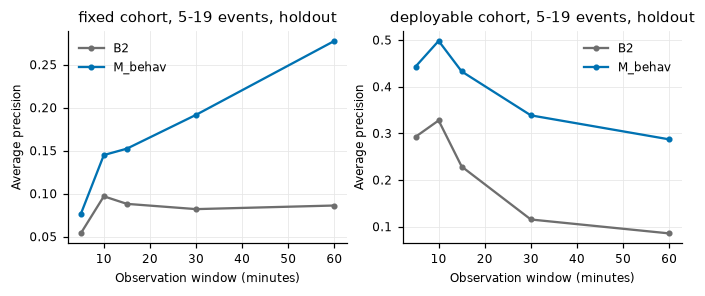

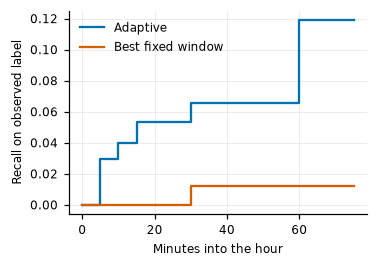

In [12]:
fig, axes = new_figure(width=7.2, height=2.5, ncols=2)
for ax, cohort in zip(axes, ("fixed", "deployable")):
    part = latency[latency.cohort == cohort]
    for model, color in (("B2", "#6E6E6E"), ("M_behav", "#0072B2")):
        rows = part[part.model == model]
        ax.plot(rows["window"], rows["ap_5-19"], marker="o", ms=3, color=color, label=model)
    ax.set_xlabel("Observation window (minutes)"); ax.set_ylabel("Average precision"); ax.set_title(f"{cohort} cohort, 5-19 events, holdout"); ax.legend()
save_figure(fig, "fig_latency_curves_final")
adaptive, behav_scores = keep[("fixed", "F3_forward_batch_excluded")]
horizon = cfg["aurt_horizon_minutes"]
mask, yt = adaptive["mask"], behav_scores["test_y"]
fig, ax = new_figure()
for key, color, label in ((("adaptive", primary), "#0072B2", "Adaptive"), (("best_fixed", primary), "#D55E00", "Best fixed window")):
    if key in adaptive["times"]:
        t = adaptive["times"][key][mask]
        ax.step(np.arange(0, horizon + 1), [((t <= p) & np.isfinite(t) & (yt[mask] == 1)).sum() / max(yt[mask].sum(), 1) for p in range(horizon + 1)], where="post", color=color, label=label)
ax.set_xlabel("Minutes into the hour"); ax.set_ylabel("Recall on observed label"); ax.legend()
save_figure(fig, "fig_recall_time_final")

## Ringkasan & cek

In [13]:
checks.add("Q19", marker.exists(), "penanda holdout tertulis sebelum label dibaca")
checks.add("kelengkapan", len(decision_table) == 6, "enam baris keputusan")
checks.raise_if_failed()
write_numbers({"delta_ap_h1a": h1a["delta"], "within_cell_auc_h1b": h1b_value, "ratio_h2a": split_dev["ratio_a1_a3"], "aurt_delta_h4a": h4a.get("delta"), "delta_ap_h5": h5["delta"], "positives_f3_5_19": f3_519_pos})
print(run.finish(n_test=data.test.height, n_pos_test=int(y.sum())))

[LULUS] Q19: penanda holdout tertulis sebelum label dibaca
[LULUS] kelengkapan: enam baris keputusan
{'notebook': '15_holdout_evaluation', 'finished_at_utc': '2026-11-10T12:22:38+00:00', 'git_commit': 'dde2836', 'duration_seconds': 346.7, 'counts': {'n_test': 32582, 'n_pos_test': 785}}
